# 42 - Análise das descrições preprocessadas e dos NCMs em 2025

**Objetivo:** entender os textos fornecidos ao TF-IDF, identificar os NCMs mais comuns e comparar a distribuição dos itens de nota nos 12 meses de 2025.

A análise textual compara `descricao_normalizada` com as três variantes experimentais produzidas no notebook 41. Ela mostra estatísticas de tamanho, tokens, termos mais comuns e exemplos. Cada descrição única entra uma vez no TF-IDF; `frequencia` registra o número de ocorrências fiscais representadas.

Para NCMs e volumes mensais, usamos os arquivos mensais de `data/interim/2025_NCMs_filtrados/`, origem da base anual do notebook 41. Aplicamos a mesma normalização do 41, incluindo a remoção opcional de stop words, e contamos somente ocorrências das descrições presentes na base carregada. Assim, contamos itens reais por NCM e mês, sem estimar a distribuição a partir de `primeiro_mes`, `ultimo_mes` ou do NCM mais frequente de cada descrição consolidada.

A tokenização textual segue o padrão usual do `TfidfVectorizer` (`(?u)\b\w\w+\b`): tokens de um caractere são ignorados. Os gráficos são exibidos no notebook; nenhuma célula grava dados ou modelos.

In [1]:
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd
from IPython.display import display

# Execute a partir da raiz do reposit?rio ou da pasta notebooks.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_PATH = Path(
    "data/processed/2025_NCMs_filtrados_semstopwords-amostra10000-seed42/"
    "2025_NCMs_filtrados_semstopwords-amostra10000-seed42-202501-202512.parquet"
)


MONTHLY_ITEMS_DIR = Path("data/interim/2025_NCMs_filtrados")
ANALYSIS_YEAR = 2025
ANALYSIS_MONTHS = pd.period_range(f"{ANALYSIS_YEAR}-01", f"{ANALYSIS_YEAR}-12", freq="M").astype(str)
MONTH_LABELS = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
ITEM_DESCRIPTION_COLUMN = "DESCRIÇÃO DO PRODUTO/SERVIÇO"
NCM_COLUMN = "CÓDIGO NCM/SH"
NCM_LABEL_COLUMN = "NCM/SH (TIPO DE PRODUTO)"
NUMERIC_SEQUENCE_PATTERN = r"\d{6,}"  # Mesmo critério do notebook 41.

# O nome padrão do notebook 41 identifica a base sem stop words.
# Ajuste estes parâmetros se usar outro nome ou uma lista personalizada no 41.
REMOVER_STOP_WORDS = "_semstopwords" in DATASET_PATH.stem
STOP_WORDS = {
    "a", "as", "o", "os", "de", "da", "das", "do", "dos", "e", "em",
    "no", "na", "nos", "nas", "ao", "aos", "um", "uma", "uns", "umas",
}

FREQUENCY_COLUMN = "frequencia"
DESCRIPTION_COLUMNS = {
    "Normalizada (entrada principal)": "descricao_normalizada",
    "Abrevia??es e unidades": "descricao_abreviacoes_unidades",
    "Espa?amento n?mero-unidade": "descricao_numero_unidade_padronizada",
    "N?meros mascarados": "descricao_numeros_mascarados",
}
TOP_N = 30
TOP_N_NCM = 30
SAMPLE_SIZE = 30
RANDOM_SEED = 42

ANALYSIS_COLUMN = DESCRIPTION_COLUMNS["Normalizada (entrada principal)"]

INPUT_PATH = PROJECT_ROOT / DATASET_PATH
INPUT_PATH

WindowsPath('c:/Users/samuel.simao/Sources/Nofis-Classifier/data/processed/2025_NCMs_filtrados_semstopwords-amostra10000-seed42/2025_NCMs_filtrados_semstopwords-amostra10000-seed42-202501-202512.parquet')

## Fun??es da an?lise

As tabelas de palavras incluem duas perspectivas: contagem de tokens entre descri??es ?nicas e contagem ponderada por `frequencia`. A primeira descreve os documentos que entram no TF-IDF; a segunda aproxima quantas ocorr?ncias dos itens fiscais cada termo representa.

In [2]:
def tokenize_description(value: object) -> list[str]:
    """Tokenize a description using scikit-learn's default word token pattern."""
    if pd.isna(value):
        return []
    return re.findall(r"(?u)\b\w\w+\b", str(value).lower())


def summarize_description_column(frame: pd.DataFrame, column: str) -> dict[str, float]:
    """Calculate document-level text length and token statistics for a column."""
    tokens_by_row = frame[column].fillna("").map(tokenize_description)
    token_counts = tokens_by_row.map(len)
    character_counts = frame[column].fillna("").astype(str).str.len()
    return {
        "descri??es ?nicas": len(frame),
        "descri??es sem token": int(token_counts.eq(0).sum()),
        "tokens totais (documentos)": int(token_counts.sum()),
        "tokens por descri??o ? mediana": float(token_counts.median()),
        "tokens por descri??o ? p90": float(token_counts.quantile(0.9)),
        "tokens por descri??o ? m?ximo": int(token_counts.max()),
        "caracteres por descri??o ? mediana": float(character_counts.median()),
        "vocabul?rio (tokens distintos)": int(len({token for tokens in tokens_by_row for token in tokens})),
    }


def word_frequency_table(
    frame: pd.DataFrame, column: str, top_n: int
) -> pd.DataFrame:
    """Count tokens across unique descriptions and weighted item occurrences."""
    token_counts: dict[str, int] = {}
    weighted_counts: dict[str, int] = {}
    document_counts: dict[str, int] = {}
    weighted_document_counts: dict[str, int] = {}

    for text, frequency in zip(frame[column].fillna(""), frame[FREQUENCY_COLUMN]):
        tokens = tokenize_description(text)
        for token in tokens:
            token_counts[token] = token_counts.get(token, 0) + 1
            weighted_counts[token] = weighted_counts.get(token, 0) + int(frequency)
        for token in set(tokens):
            document_counts[token] = document_counts.get(token, 0) + 1
            weighted_document_counts[token] = weighted_document_counts.get(token, 0) + int(frequency)

    table = pd.DataFrame({
        "token": list(token_counts),
        "document_occurrences": list(token_counts.values()),
        "documents_with_token": [document_counts[token] for token in token_counts],
        "frequency_weighted_occurrences": [weighted_counts[token] for token in token_counts],
        "percentage_of_items_with_token": [
            100 * weighted_document_counts[token] / frame[FREQUENCY_COLUMN].sum()
            for token in token_counts
        ],
    })
    return table.sort_values(
        ["document_occurrences", "token"], ascending=[False, True]
    ).head(top_n).reset_index(drop=True)


def sample_descriptions(frame: pd.DataFrame, column: str, sample_size: int) -> pd.DataFrame:
    """Select a reproducible sample spanning short, middle, and long documents."""
    lengths = frame[column].fillna("").map(lambda value: len(tokenize_description(value)))
    ordered = frame.assign(_tokens=lengths).sort_values("_tokens")
    if len(ordered) <= sample_size:
        sample = ordered
    else:
        positions = [round(i * (len(ordered) - 1) / (sample_size - 1)) for i in range(sample_size)]
        sample = ordered.iloc[positions]
    return sample[[column, FREQUENCY_COLUMN, "primeiro_mes", "ultimo_mes"]].reset_index(drop=True)


def normalize_monthly_description(value: object) -> str:
    """Reproduce notebook 41's consolidation key, including optional stop words."""
    if pd.isna(value):
        return ""
    text = re.sub(NUMERIC_SEQUENCE_PATTERN, " ", str(value).strip()).lower()
    text = unicodedata.normalize("NFKD", text)
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = re.sub(r"[^a-z0-9]+", " ", text)
    tokens = text.split()
    if REMOVER_STOP_WORDS:
        tokens = [token for token in tokens if token not in STOP_WORDS]
    return " ".join(tokens)


def normalize_ncm_codes(values: pd.Series) -> pd.Series:
    """Preserve leading zeros and mark missing or malformed codes separately."""
    codes = values.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    codes = codes.str.replace(r"^(\d{4})\.(\d{2})\.(\d{2})$", r"\1\2\3", regex=True)
    valid = codes.str.fullmatch(r"\d{1,8}", na=False)
    return codes.where(valid).str.zfill(8).mask(lambda series: series.eq("00000000"))


def load_monthly_ncm_counts(dataset: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Count monthly occurrences of the descriptions represented in the loaded dataset."""
    expected_counts = dataset.groupby("descricao_normalizada")[FREQUENCY_COLUMN].sum()
    observed_counts = pd.Series(0, index=expected_counts.index, dtype="int64")
    paths = [PROJECT_ROOT / MONTHLY_ITEMS_DIR / f"{month}.parquet" for month in ANALYSIS_MONTHS]
    missing = [str(path.relative_to(PROJECT_ROOT)) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError(f"Faltam arquivos mensais; ausência não significa zero itens: {missing}")

    monthly_summaries = []
    ncm_counts = []
    for month, path in zip(ANALYSIS_MONTHS, paths):
        frame = pd.read_parquet(path, columns=[ITEM_DESCRIPTION_COLUMN, NCM_COLUMN, NCM_LABEL_COLUMN])
        descriptions = frame[ITEM_DESCRIPTION_COLUMN].map(normalize_monthly_description)
        valid_description = descriptions.ne("")
        selected = valid_description & descriptions.isin(expected_counts.index)
        valid = frame.loc[selected].copy()
        observed_counts = observed_counts.add(descriptions.loc[selected].value_counts(), fill_value=0)
        codes = normalize_ncm_codes(valid[NCM_COLUMN])
        monthly_summaries.append({
            "mes": month,
            "itens_origem": len(frame),
            "itens_excluidos_descricao": int((~valid_description).sum()),
            "itens_fora_dataset_carregado": int((valid_description & ~selected).sum()),
            "total_itens": len(valid),
            "itens_sem_ncm_valido": int(codes.isna().sum()),
        })
        valid["ncm"] = codes
        valid["descricao_ncm"] = valid[NCM_LABEL_COLUMN].fillna("Sem descrição NCM").astype(str)
        counts = (
            valid.dropna(subset=["ncm"])
            .groupby(["ncm", "descricao_ncm"], as_index=False)
            .size().rename(columns={"size": "total_itens"})
        )
        ncm_counts.append(counts.assign(mes=month))
        print(
            f"{month}: {len(valid):,} itens do dataset carregado; "
            f"{int((~valid_description).sum()):,} excluídos por descrição; "
            f"{int((valid_description & ~selected).sum()):,} fora do recorte"
        )

    # Comparar por descrição evita que diferenças se compensem no total anual.
    comparison = pd.DataFrame({"esperado": expected_counts, "observado": observed_counts}).fillna(0)
    mismatches = comparison.loc[comparison["esperado"].ne(comparison["observado"])]
    if not mismatches.empty:
        raise ValueError(
            "As ocorrências mensais não reproduzem as frequências do dataset carregado. "
            f"Esperado: {int(expected_counts.sum()):,}; observado: {int(observed_counts.sum()):,}. "
            "Confira MONTHLY_ITEMS_DIR, o período, REMOVER_STOP_WORDS e STOP_WORDS "
            "(a mesma lista usada no notebook 41). Amostras devem preservar todas as "
            "ocorrências das descrições selecionadas, como no modo consolidado; "
            "uma amostra de linhas com duplicatas exige identificar os itens originais. "
            f"Primeiras divergências: {mismatches.head().to_dict(orient='index')}"
        )

    monthly = pd.DataFrame(monthly_summaries).set_index("mes").reindex(ANALYSIS_MONTHS)
    monthly.index.name = "mes"
    return monthly, pd.concat(ncm_counts, ignore_index=True)


def format_item_count(value, position=None):
    """Format chart counts with Brazilian thousands separators."""
    return f"{value:,.0f}".replace(",", ".")

## 1. Carregar e validar a base

A entrada ? o Parquet processado gerado pelo notebook 41. Cada linha representa uma descri??o normalizada ?nica; `frequencia` registra quantas linhas originais foram consolidadas nela.

In [3]:
if not INPUT_PATH.exists():
    raise FileNotFoundError(f"Dataset n?o encontrado: {INPUT_PATH}")

df = pd.read_parquet(INPUT_PATH)
required_columns = [FREQUENCY_COLUMN, "primeiro_mes", "ultimo_mes", *DESCRIPTION_COLUMNS.values()]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise KeyError(f"Colunas esperadas ausentes: {missing_columns}")
if df.empty:
    raise ValueError("O dataset est? vazio.")

print(f"Arquivo: {INPUT_PATH}")
print(f"Descri??es ?nicas: {len(df):,}")
print(f"Ocorr?ncias representadas por frequencia: {int(df[FREQUENCY_COLUMN].sum()):,}")
print(f"Per?odo: {df['primeiro_mes'].min()} a {df['ultimo_mes'].max()}")
display(df.head())

Arquivo: c:\Users\samuel.simao\Sources\Nofis-Classifier\data\processed\2025_NCMs_filtrados_semstopwords-amostra10000-seed42\2025_NCMs_filtrados_semstopwords-amostra10000-seed42-202501-202512.parquet
Descri??es ?nicas: 10,000
Ocorr?ncias representadas por frequencia: 60,396
Per?odo: 2025-01 a 2025-12


,descricao_normalizada,frequencia,descricao_original_exemplo,descricoes_originais_distintas,primeiro_mes,ultimo_mes,meses_presentes,descricao_abreviacoes_unidades,descricao_numero_unidade_padronizada,descricao_numeros_mascarados,codigo_ncm_mais_frequente,ncm_tipo_mais_frequente
0,0 25kg adesivo epoxi massa bi componente com b...,1,"0,25KG DE ADESIVO EPOXI MASSA BI COMPONENTE CO...",1,2025-12,2025-12,1,0 25kg adesivo epoxi massa bi componente com b...,0 25 kg adesivo epoxi massa bi componente com ...,numero kg adesivo epoxi massa bi componente co...,35061090.0,Outros produtos de qualquer espécie utilizados...
1,00007 detergente composicao tensoativo anionic...,1,"00007 - DETERGENTE, COMPOSICAO TENSOATIVO ANIO...",1,2025-04,2025-04,1,00007 detergente composicao tensoativo anionic...,00007 detergente composicao tensoativo anionic...,numero detergente composicao tensoativo anioni...,34029039.0,Outras preparações para lavagem (detergentes)
2,0001 petit four,7,0001 - PETIT FOUR,1,2025-01,2025-12,7,0001 petit four,0001 petit four,numero petit four,19059090.0,"Outros produtos de padaria, pastelaria, indúst..."
3,00054 bolo alimenticio sabor maracuja tipo tor...,2,"00054 - BOLO ALIMENTICIO, SABOR MARACUJA, TIPO...",1,2025-04,2025-05,2,00054 bolo alimenticio sabor maracuja tipo tor...,00054 bolo alimenticio sabor maracuja tipo tor...,numero bolo alimenticio sabor maracuja tipo to...,19059090.0,"Outros produtos de padaria, pastelaria, indúst..."
4,0009 saco plastico ksf 1050x2500,1,0009/SACO PLASTICO KSF 1050X2500,1,2025-11,2025-11,1,0009 saco plastico ksf 1050x2500,0009 saco plastico ksf 1050x2500,numero saco plastico ksf 1050x2500,39232910.0,"Sacos, bolsas e cartuchos, de outros plásticos..."


## 2. O que ser? entregue ao TF-IDF?

Compare tamanho das descri??es, quantidade de tokens, textos sem tokens utiliz?veis pelo tokenizador padr?o e tamanho do vocabul?rio de cada representa??o.

,descri??es ?nicas,descri??es sem token,tokens totais (documentos),tokens por descri??o ? mediana,tokens por descri??o ? p90,tokens por descri??o ? m?ximo,caracteres por descri??o ? mediana,vocabul?rio (tokens distintos)
Normalizada (entrada principal),10000.000000,1.000000,56107.000000,5.0,9.0,25.000000,31.0,10820.000000
Abrevia??es e unidades,10000.000000,1.000000,56967.000000,5.0,9.0,24.000000,31.0,10810.000000
Espa?amento n?mero-unidade,10000.000000,1.000000,56716.000000,5.0,9.0,25.000000,31.0,10494.000000
N?meros mascarados,10000.000000,0.000000,58120.000000,5.0,9.0,23.000000,34.0,9649.000000


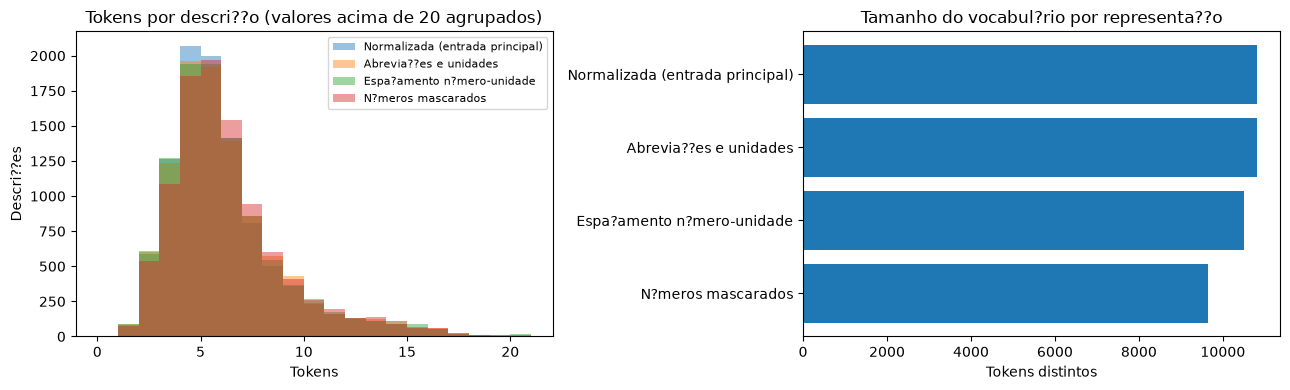

In [4]:
description_summary = pd.DataFrame(
    {
        label: summarize_description_column(df, column)
        for label, column in DESCRIPTION_COLUMNS.items()
    }
).T

display(description_summary.style.format({
    "tokens por descri??o ? mediana": "{:.1f}",
    "tokens por descri??o ? p90": "{:.1f}",
    "caracteres por descri??o ? mediana": "{:.1f}",
}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, column in DESCRIPTION_COLUMNS.items():
    token_lengths = df[column].fillna("").map(lambda value: len(tokenize_description(value)))
    axes[0].hist(token_lengths.clip(upper=20), bins=range(0, 22), alpha=0.45, label=label)
axes[0].set(title="Tokens por descri??o (valores acima de 20 agrupados)", xlabel="Tokens", ylabel="Descri??es")
axes[0].legend(fontsize=8)

summary_plot = description_summary["vocabul?rio (tokens distintos)"].sort_values()
axes[1].barh(summary_plot.index, summary_plot.values)
axes[1].set(title="Tamanho do vocabul?rio por representa??o", xlabel="Tokens distintos")
fig.tight_layout()
plt.show()

## 3. Palavras mais comuns

A tabela abaixo conta tokens repetidos dentro de uma descri??o como ocorr?ncias repetidas, assim como o vetorizador padr?o. ?Descri??es com token? conta presen?a uma ?nica vez por documento. A ordena??o principal ? pela representa??o normalizada; repita a c?lula trocando `ANALYSIS_COLUMN` para inspecionar outra variante.

,token,document_occurrences,documents_with_token,frequency_weighted_occurrences,percentage_of_items_with_token
0,tipo,530,507,2418,3.76
1,com,495,471,1827,2.94
2,kg,395,380,3398,5.58
3,saco,360,359,1594,2.64
4,100,341,326,1106,1.78
5,material,340,310,761,1.19
6,papel,338,335,1740,2.88
7,para,315,311,1402,2.31
8,1kg,306,298,1861,3.06
9,un,295,268,1208,1.92


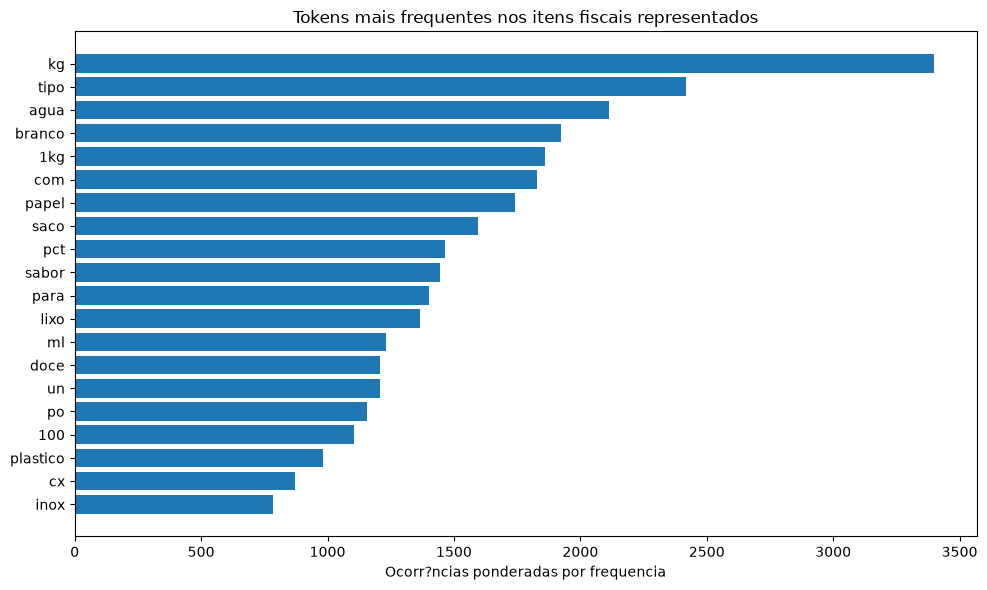

In [5]:
common_words = word_frequency_table(df, ANALYSIS_COLUMN, TOP_N)
common_words["percentage_of_items_with_token"] = common_words["percentage_of_items_with_token"].round(2)
display(common_words)

weighted_words = common_words.nlargest(20, "frequency_weighted_occurrences").sort_values(
    "frequency_weighted_occurrences"
)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(weighted_words["token"], weighted_words["frequency_weighted_occurrences"])
ax.set(title="Tokens mais frequentes nos itens fiscais representados", xlabel="Ocorr?ncias ponderadas por frequencia")
fig.tight_layout()
plt.show()

## 4. Comparar vocabul?rios e termos dominantes

Este quadro ajuda a identificar se as regras experimentais juntam variantes lexicais ou preservam tokens de quantidade. A contagem ponderada serve para interpretar o volume de compras representado, enquanto a contagem de documentos descreve a matriz TF-IDF quando cada descri??o ?nica ? uma linha.

In [6]:
variant_word_tables = {}
for label, column in DESCRIPTION_COLUMNS.items():
    variant_word_tables[label] = word_frequency_table(df, column, TOP_N)

variant_top_words = pd.concat(
    [table.assign(representation=label) for label, table in variant_word_tables.items()],
    ignore_index=True,
)[["representation", "token", "document_occurrences", "documents_with_token", "frequency_weighted_occurrences"]]

display(variant_top_words)

,representation,token,document_occurrences,documents_with_token,frequency_weighted_occurrences
0,Normalizada (entrada principal),tipo,530,507,2418
1,Normalizada (entrada principal),com,495,471,1827
2,Normalizada (entrada principal),kg,395,380,3398
3,Normalizada (entrada principal),saco,360,359,1594
4,Normalizada (entrada principal),100,341,326,1106
...,...,...,...,...,...
115,N?meros mascarados,branca,167,167,708
116,N?meros mascarados,cola,159,157,938
117,N?meros mascarados,farinha,157,156,1408
118,N?meros mascarados,cor,154,153,356


## 5. Inspecionar descri??es concretas

A amostra percorre descri??es curtas, medianas e longas. Leia os exemplos junto aos termos frequentes: abrevia??es, n?meros, unidades e ru?do textual podem afetar os documentos e o vocabul?rio do TF-IDF.

In [7]:
description_samples = sample_descriptions(df, ANALYSIS_COLUMN, SAMPLE_SIZE)
display(description_samples)

# Compara??o lado a lado das representa??es para uma amostra reproduz?vel.
sample_indices = df.sample(min(SAMPLE_SIZE, len(df)), random_state=RANDOM_SEED).index
comparison_columns = [FREQUENCY_COLUMN, *DESCRIPTION_COLUMNS.values()]
display(df.loc[sample_indices, comparison_columns].sort_values(FREQUENCY_COLUMN, ascending=False).reset_index(drop=True))

,descricao_normalizada,frequencia,primeiro_mes,ultimo_mes
0,1,1,2025-06,2025-06
1,reservatorio solv,1,2025-12,2025-12
2,xicara porcelana preta,2,2025-01,2025-01
3,lemon peper 1kg,2,2025-07,2025-11
4,esponja limpabela d face,1,2025-05,2025-05
5,biscoito tipo champigne,2,2025-05,2025-05
6,aparelhio equipamento tipo bosu,1,2025-11,2025-11
7,carne ave tipo reu,1,2025-12,2025-12
8,cola branca extra 1 kg,1,2025-02,2025-02
9,sal ref lebre 1kg,15,2025-02,2025-11


,frequencia,descricao_normalizada,descricao_abreviacoes_unidades,descricao_numero_unidade_padronizada,descricao_numeros_mascarados
0,36,mini empada kg,mini empada kg,mini empada kg,mini empada kg
1,19,agua sem gas,agua sem gas,agua sem gas,agua sem gas
2,13,pao sovado 100 g,pao sovado 100 g,pao sovado 100 g,pao sovado numero g
3,10,mistura alimentica,mistura alimentica,mistura alimentica,mistura alimentica
4,5,taca acrilico 40 ml pct c 10 und,taca acrilico 40 ml pacote com 10 un,taca acrilico 40 ml pct c 10 und,taca acrilico numero ml pct c numero und
5,3,mekal d 100 5l,mekal d 100 5l,mekal d 100 5 l,mekal d numero l
6,3,vinagre anchieta 750ml alcool,vinagre anchieta 750ml alcool,vinagre anchieta 750 ml alcool,vinagre anchieta numero ml alcool
7,2,ah caldeirao standart 30,ah caldeirao standart 30,ah caldeirao standart 30,ah caldeirao standart numero
8,2,refrigerante laranja fanta pet 2lt,refrigerante laranja fanta pet 2lt,refrigerante laranja fanta pet 2lt,refrigerante laranja fanta pet 2lt
9,2,versatil desinfetante talco bactericida cx 4x5lt,versatil desinfetante talco bactericida cx 4x5lt,versatil desinfetante talco bactericida cx 4x5lt,versatil desinfetante talco bactericida cx 4x5lt


## 6. Carregar as ocorrências mensais de 2025

Cada ocorrência nos Parquets mensais conta como **um item de nota**, sem somar `QUANTIDADE` nem contar notas distintas. O recorte contém apenas os NCMs selecionados no notebook 21 e as descrições presentes em `DATASET_PATH`.

O mês é a competência do arquivo `YYYY-MM.parquet`, como no notebook 41. Reproduzimos a normalização, a remoção de sequências de seis ou mais dígitos e, quando habilitada, a remoção de stop words. `REMOVER_STOP_WORDS` é inicialmente inferido do nome padrão `_semstopwords`; a lista local deve coincidir com a usada no 41. Descrições vazias são excluídas e contadas separadamente das descrições fora do dataset carregado.

Para uma amostra de descrições únicas, são contadas todas as ocorrências mensais das descrições selecionadas, preservando o significado de `frequencia`. Uma amostra de linhas com duplicatas não preserva essa informação por descrição e não pode ser reconstruída por este método; a validação acusa a divergência em vez de apresentar contagens do dataset completo como se fossem da amostra.

Todos os 12 arquivos são obrigatórios: um mês ausente não é interpretado como zero. As frequências são conferidas **por descrição**, além do total anual. Itens sem NCM válido permanecem no total mensal, mas ficam fora do ranking de códigos.


In [8]:
monthly_item_summary, monthly_ncm_counts = load_monthly_ncm_counts(df)
total_items_2025 = int(monthly_item_summary["total_itens"].sum())
if total_items_2025 == 0:
    raise ValueError("Nenhum item válido encontrado nos 12 meses de 2025.")
if total_items_2025 != int(df[FREQUENCY_COLUMN].sum()):
    raise ValueError(
        "O total mensal diverge da frequência da base consolidada. "
        "Confira o período, os filtros e os caminhos configurados."
    )

monthly_item_summary["percentual_ano"] = 100 * monthly_item_summary["total_itens"] / total_items_2025
display(monthly_item_summary.style.format({"percentual_ano": "{:.2f}%"}))
print(f"Total de itens em {ANALYSIS_YEAR}: {total_items_2025:,}")
print(f"Itens sem NCM válido: {monthly_item_summary['itens_sem_ncm_valido'].sum():,}")

2025-01: 3,089 itens do dataset carregado; 0 excluídos por descrição; 44,117 fora do recorte
2025-02: 4,173 itens do dataset carregado; 2 excluídos por descrição; 57,721 fora do recorte
2025-03: 4,908 itens do dataset carregado; 0 excluídos por descrição; 63,478 fora do recorte
2025-04: 5,038 itens do dataset carregado; 0 excluídos por descrição; 65,023 fora do recorte
2025-05: 5,824 itens do dataset carregado; 1 excluídos por descrição; 75,862 fora do recorte
2025-06: 5,003 itens do dataset carregado; 0 excluídos por descrição; 66,934 fora do recorte
2025-07: 5,589 itens do dataset carregado; 0 excluídos por descrição; 74,987 fora do recorte
2025-08: 5,085 itens do dataset carregado; 0 excluídos por descrição; 67,891 fora do recorte
2025-09: 5,341 itens do dataset carregado; 1 excluídos por descrição; 74,437 fora do recorte
2025-10: 5,728 itens do dataset carregado; 0 excluídos por descrição; 74,774 fora do recorte
2025-11: 5,680 itens do dataset carregado; 0 excluídos por descrição; 

,itens_origem,itens_excluidos_descricao,itens_fora_dataset_carregado,total_itens,itens_sem_ncm_valido,percentual_ano
mes,,,,,,
2025-01,47206,0,44117,3089,0,5.11%
2025-02,61896,2,57721,4173,0,6.91%
2025-03,68386,0,63478,4908,0,8.13%
2025-04,70061,0,65023,5038,0,8.34%
2025-05,81687,1,75862,5824,0,9.64%
2025-06,71937,0,66934,5003,0,8.28%
2025-07,80576,0,74987,5589,0,9.25%
2025-08,72976,0,67891,5085,0,8.42%
2025-09,79779,1,74437,5341,0,8.84%


Total de itens em 2025: 60,396
Itens sem NCM válido: 0


## 7. NCMs mais comuns no dataset anual

O ranking usa o total de ocorrências dos itens nos 12 meses, com desempate pelo código NCM. O percentual considera **todos os itens válidos do dataset**, inclusive eventuais itens sem NCM válido. A descrição exibida é o rótulo mais frequente de cada código nos dados, sem consulta a uma tabela externa.

Os valores se referem ao dataset carregado, após o mesmo pré-processamento e o recorte pelas descrições selecionadas.


,ncm,total_itens,descricao_ncm,percentual_itens_ano
0,85061019,3679,"Outras pilhas alcalinas, de dióxido de manganês",6.09%
1,21069090,3384,Outras preparações alimentícias,5.60%
2,16010000,2410,"Enchidos e produtos semelhantes, de carne, de miudezas ou de sangue; preparações alimentícias à base de tais produtos",3.99%
3,19059090,1978,"Outros produtos de padaria, pastelaria, indústria de biscoitos, etc",3.28%
4,39269090,1922,Outras obras de plásticos,3.18%
5,96039000,1836,"Outras vassouras, escovas, pincéis, espanadores, rodos, etc.",3.04%
6,34029039,1448,Outras preparações para lavagem (detergentes),2.40%
7,22021000,1411,"Águas, incluindo as águas minerais e as águas gaseificadas, adicionadas de açúcar ou de outros edulcorantes ou aromatizadas",2.34%
8,22011000,1325,"Águas minerais e águas gaseificadas, não adicionadas de açúcar ou de outros edulcorantes nem aromatizadas",2.19%
9,39241000,1216,"Serviços de mesa e outros utensílios de mesa ou de cozinha, de plásticos",2.01%


NCMs distintos: 235
Participação dos 30 principais NCMs: 56.11%


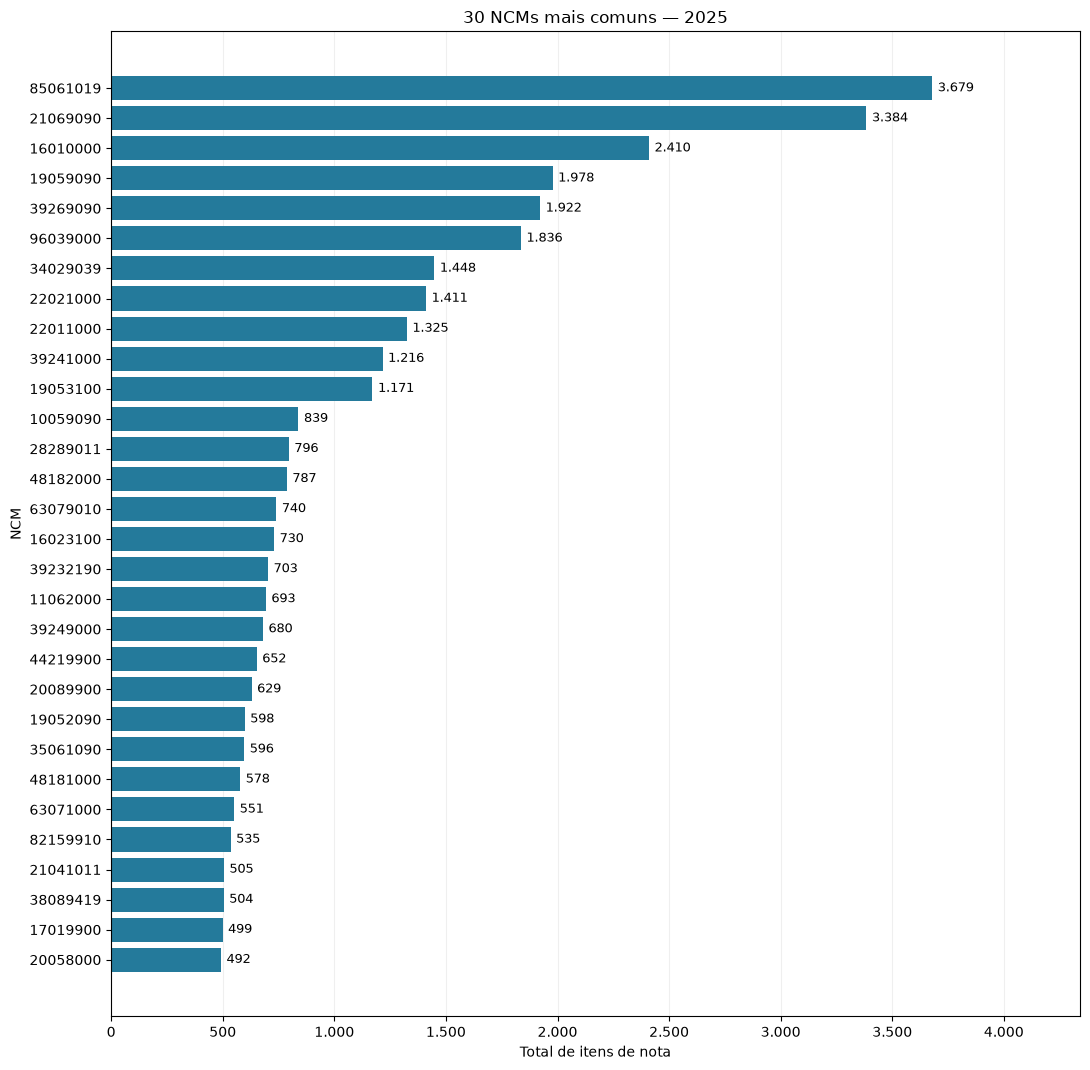

In [9]:
ncm_totals = (
    monthly_ncm_counts.groupby("ncm", as_index=False)["total_itens"].sum()
    .sort_values(["total_itens", "ncm"], ascending=[False, True])
)
if ncm_totals.empty:
    raise ValueError("Não há NCMs válidos para gerar o ranking e os gráficos mensais.")
ncm_labels = (
    monthly_ncm_counts.groupby(["ncm", "descricao_ncm"], as_index=False)["total_itens"].sum()
    .sort_values(["total_itens", "descricao_ncm"], ascending=[False, True])
    .drop_duplicates("ncm")[["ncm", "descricao_ncm"]]
)
ncm_ranking = ncm_totals.merge(ncm_labels, on="ncm", how="left")
ncm_ranking["percentual_itens_ano"] = 100 * ncm_ranking["total_itens"] / total_items_2025
top_ncms = ncm_ranking.head(TOP_N_NCM).copy()
display(top_ncms.style.format({"percentual_itens_ano": "{:.2f}%"}))
print(f"NCMs distintos: {len(ncm_ranking):,}")
print(f"Participação dos {len(top_ncms)} principais NCMs: {top_ncms['percentual_itens_ano'].sum():.2f}%")

fig, ax = plt.subplots(figsize=(11, max(5, len(top_ncms) * 0.36)))
bars = ax.barh(top_ncms["ncm"], top_ncms["total_itens"], color="#247a9b")
ax.invert_yaxis()
ax.bar_label(bars, labels=[format_item_count(value) for value in top_ncms["total_itens"]], padding=4, fontsize=9)
ax.set(title=f"{len(top_ncms)} NCMs mais comuns — {ANALYSIS_YEAR}", xlabel="Total de itens de nota", ylabel="NCM")
ax.xaxis.set_major_formatter(FuncFormatter(format_item_count))
ax.set_xlim(0, top_ncms["total_itens"].max() * 1.18)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 8. Distribuição do total de itens por mês

As barras incluem todos os NCMs do recorte, além de eventuais itens sem NCM válido. O valor acima de cada barra é a contagem de itens; o percentual mostra a participação daquele mês no total anual. Diferenças de volume podem refletir a cobertura do dataset e não devem ser interpretadas isoladamente como mudança no consumo.

Os valores se referem ao dataset carregado, após o mesmo pré-processamento e o recorte pelas descrições selecionadas.


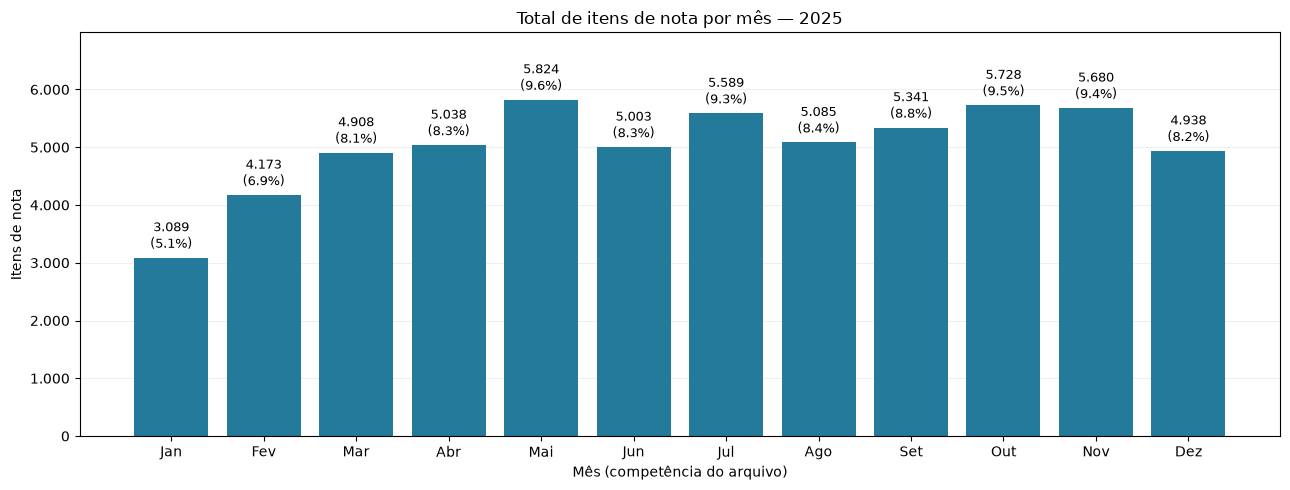

In [10]:
fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(MONTH_LABELS, monthly_item_summary["total_itens"], color="#247a9b")
ax.bar_label(
    bars,
    labels=[
        f"{format_item_count(row.total_itens)}\n({row.percentual_ano:.1f}%)"
        for row in monthly_item_summary.itertuples()
    ],
    padding=4, fontsize=9,
)
ax.set(title=f"Total de itens de nota por mês — {ANALYSIS_YEAR}", xlabel="Mês (competência do arquivo)", ylabel="Itens de nota")
ax.yaxis.set_major_formatter(FuncFormatter(format_item_count))
ax.set_ylim(0, monthly_item_summary["total_itens"].max() * 1.2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 9. Distribuição mensal dos NCMs mais comuns

Mantemos os mesmos NCMs do ranking anual em todos os meses. O primeiro mapa mostra as **contagens absolutas**; o segundo, a **participação de cada NCM no total de itens daquele mês**. Essa segunda perspectiva permite comparar meses com volumes diferentes. As colunas percentuais não somam 100%, pois o gráfico mostra apenas os principais NCMs.

Zeros indicam ausência de ocorrências de um código em um arquivo mensal carregado. Códigos com menos de oito dígitos recebem zeros à esquerda; códigos ausentes, zerados ou com formato inválido não entram no ranking. A tabela permite consultar os valores exatos.

Os valores se referem ao dataset carregado, após o mesmo pré-processamento e o recorte pelas descrições selecionadas.


mes,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
ncm,,,,,,,,,,,,
85061019,182,288,340,341,316,299,390,316,304,315,333,255
21069090,247,297,236,273,316,236,262,262,320,345,305,285
16010000,99,115,199,191,209,193,240,160,237,282,250,235
19059090,90,106,168,177,214,177,165,140,209,182,184,166
39269090,67,87,142,135,169,138,191,210,191,216,189,187
96039000,83,147,169,147,123,144,163,312,111,178,134,125
34029039,53,257,56,50,267,34,37,271,49,73,53,248
22021000,50,76,102,87,153,112,150,100,117,166,156,142
22011000,73,88,114,113,137,97,116,92,113,120,139,123


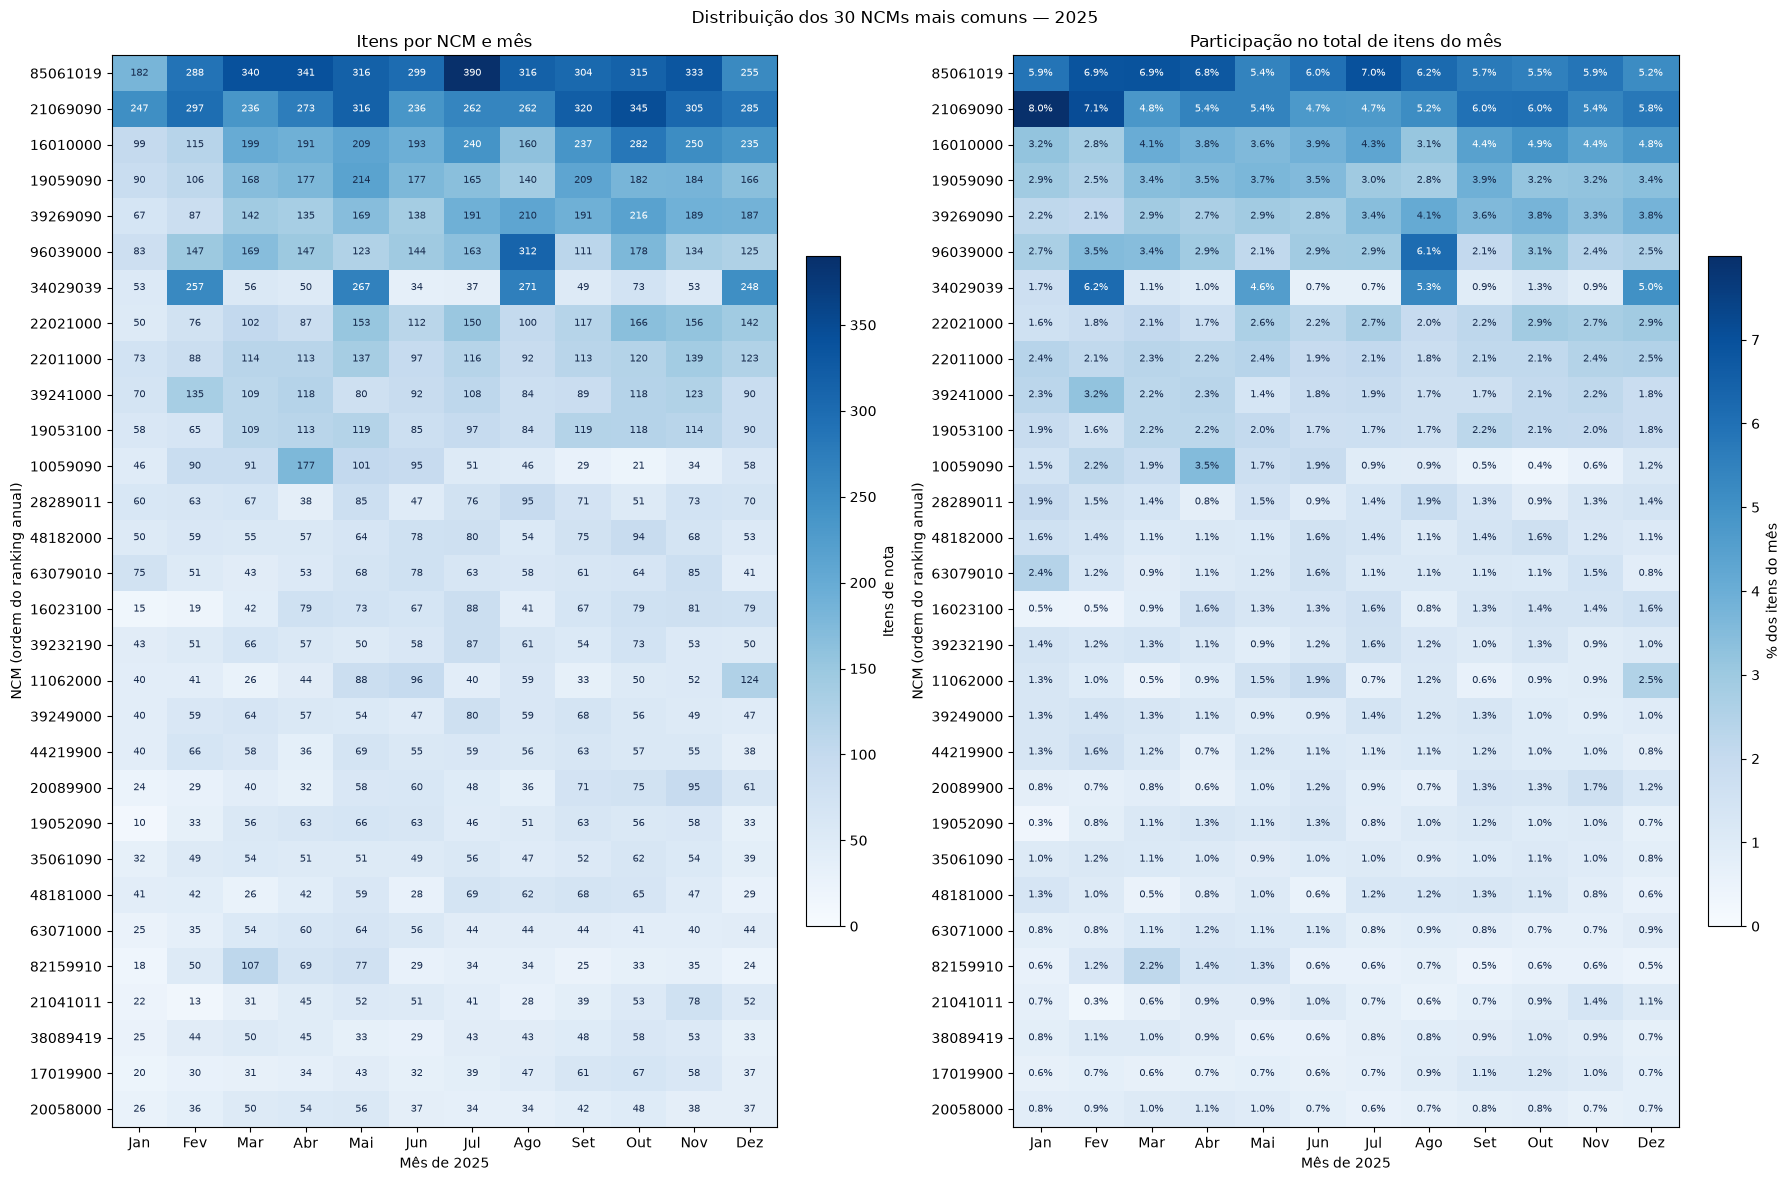

In [11]:
ncm_by_month = (
    monthly_ncm_counts.pivot_table(index="ncm", columns="mes", values="total_itens", aggfunc="sum", fill_value=0)
    .reindex(index=top_ncms["ncm"], columns=ANALYSIS_MONTHS, fill_value=0)
    .fillna(0).astype("int64")
)
ncm_monthly_share = ncm_by_month.div(monthly_item_summary["total_itens"].replace(0, float("nan")), axis="columns") * 100
display(ncm_by_month)

fig, axes = plt.subplots(1, 2, figsize=(18, max(6, len(top_ncms) * 0.4)))
for ax, values, title, colorbar_label, is_percentage in [
    (axes[0], ncm_by_month, "Itens por NCM e mês", "Itens de nota", False),
    (axes[1], ncm_monthly_share, "Participação no total de itens do mês", "% dos itens do mês", True),
]:
    heatmap = ax.imshow(values.to_numpy(dtype=float), aspect="auto", cmap="Blues", vmin=0)
    ax.set_xticks(range(12), MONTH_LABELS)
    ax.set_yticks(range(len(top_ncms)), ncm_by_month.index)
    ax.set(title=title, xlabel=f"Mês de {ANALYSIS_YEAR}", ylabel="NCM (ordem do ranking anual)")
    colorbar = fig.colorbar(heatmap, ax=ax, fraction=0.046, pad=0.04)
    colorbar.set_label(colorbar_label)
    maximum = float(values.max().max())
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            value = values.iat[row, column]
            label = "—" if pd.isna(value) else (f"{value:.1f}%" if is_percentage else format_item_count(value))
            ax.text(column, row, label, ha="center", va="center", fontsize=7,
                    color="white" if pd.notna(value) and value > maximum * 0.55 else "#172b4d")
fig.suptitle(f"Distribuição dos {len(top_ncms)} NCMs mais comuns — {ANALYSIS_YEAR}")
fig.tight_layout()
plt.show()

## 10. Pontos para decidir antes do TF-IDF

Use os resultados para registrar suas decis?es:

- **Representa??o:** qual coluna ser? entrada: texto normalizado, unidades/abrevia??es padronizadas, espa?amento can?nico ou n?meros mascarados?
- **Tokens curtos e ru?do:** h? termos frequentes que deveriam ser mantidos, tratados como stopwords ou normalizados? Revise exemplos antes de excluir conte?do.
- **N?meros e unidades:** os tamanhos/quantidades ajudam a distinguir produtos ou criam fragmenta??o excessiva?
- **Documentos ?nicos versus frequ?ncia:** o fluxo atual representa cada descri??o ?nica uma vez; avalie separadamente se o objetivo pede peso por frequ?ncia.
- **Par?metros do vetorizador:** `ngram_range`, `min_df`, `max_df` e `max_features` devem ser comparados no notebook 45, com base no vocabul?rio e nos exemplos observados.

Este notebook ? explorat?rio: as contagens n?o determinam, sozinhas, quais termos devem ser removidos.